In [30]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import optax
from flax import linen as nn
from ehtim.observing.obs_helpers import ftmatrix
from collections import OrderedDict as odict

sys.path.insert(0, '..')  # Running from notebooks/

import kine.model as mo
import kine.trainer as tr
import kine.utils as ut
import kine.video as vi

# Fix some JAX compatibility issues
if not hasattr(jax, 'tree_map'):
    jax.tree_map = jax.tree.map

In [20]:
# Read data, first line is column names
data = np.loadtxt('../data/DL_Tau_selfcal_cont_bin60s_1chan_1freq.txt', skiprows=1)

# Sample fourier coordinates, in wavelengths
u, v = data[:, 4], data[:, 5]

xx = data[:, 6] + 1j * data[:, 7]
yy = data[:, 8] + 1j * data[:, 9]
w_xx = data[:, 10]
w_yy = data[:, 11]

print(f'{len(data)} rows')

6486 rows


### Step 1: XX and YY $\rightarrow$ Stokes I

The thesis defins the coherency matrix for electric-field correlations for circular feeds, then expresses it in terms of Stokes visibilities:

$$
\begin{aligned}
\rho_{ij} &=
\begin{bmatrix}
\langle E_i^R(E_j^R)^*\rangle & \langle E_i^R(E_j^L)^*\rangle \\
\langle E_i^L(E_j^R)^*\rangle & \langle E_i^L(E_j^L)^*\rangle
\end{bmatrix} &&\text{(Thesis, Eq. 2.10)}\\ &=
\begin{bmatrix}
V_I+V_V & V_Q+iV_U \\
V_Q-iV_U & V_I-V_V
\end{bmatrix}_{ij} &&\text{(Thesis, Eq. 2.11)}
\end{aligned}
$$

Let $Q'$ be the linear polarization. For this, I refer to Eq. 8.1-8.5 of the [Alma Technical Handbook](https://almascience.nrao.edu/documents-and-tools/cycle4/alma-technical-handbook). The given table uses linear feeds, so the corresponding diagonal terms give a complex average (not amplitude alone):

$$
\begin{aligned}
V_{XX} &= V_I + V_{Q'}, \\
V_{YY} &= V_I - V_{Q'}, \\
V_{XX} + V_{YY}
&= (V_I + V_{Q'}) + (V_I - V_{Q'}) \\
&= 2V_I, \\
V_I &= \frac{V_{XX}+V_{YY}}{2}
\end{aligned}
$$

We assume the table weights are inverse variances, $w_{XX} = 1/\sigma^2_{XX}$ and $w_{YY} = 1/\sigma^2_{YY}$.  For the independent XX and YY errors:
$$
\begin{align*}
    \sigma^2_I &= \text{Var} \left(\frac{V_{XX} + V_{YY}}{2} \right) \\
    &= \frac{1}{4} \left[ \text{Var}(V_{XX}) + \text{Var}(V_{YY}) \right] &&(\text{errors are independent}) \\
    &= \frac{\sigma_{XX}^2 + \sigma_{YY}^2}{4} \\
    &= \frac{1}{4} \left( \frac{1}{w_{XX}} + \frac{1}{w_{YY}} \right) \\
    \sigma_I &= \frac{1}{2} \sqrt{\frac{1}{w_{XX}} + \frac{1}{w_{YY}}}
\end{align*}
$$

In [21]:
# Average the complex correlations
vis_i = (xx + yy) / 2

sigma_i = np.sqrt(1 / w_xx + 1 / w_yy) / 2
# sigma_i = np.sqrt(1 / w_xx**2 + 1 / w_yy**2) / 2  # If weight = 1/sigma

### Step 2: Estimating/picking an image grid

We have the interferometric resolution $\theta \simeq \lambda/B_{\max}$ (Thesis, Eq. 2.2). Our data table gives the projected baseline coordinates $u$ and $v$ in wavelenghts, so applying that estimate to the longest sampled baseline gives:
$$
\theta_{\mathrm{nominal}}
\simeq \frac{1}{\max_m\sqrt{u_m^2+v_m^2}}
\simeq 0.094\ \text{arcsec}.
$$

We choose an image grid that is 2 arcsec wide with $N=64$ pixels per side. Each pixel is therefore $p=2/64=0.03125$ arsec wide (roughly 3 pixels across the nominal resolution). The longest sampled baseline here sets the angular resolution, so we know each pixel is small enough to represent that detail (and choosing smaller pixels will not further improve resolution). 



### Step 3: Image $\rightarrow$ observed visibilities

Let $x$ and $y$ be sky angles in radians (analgous to RA/DEC), and $u$ and $v$ be baseline coordinates in wavelengths. One visibility corresponds to one Fourier sample:
$$
V(u,v)=\iint I(x,y)e^{-2\pi i(ux+vy)}\,dx\,dy \quad \text{(Thesis, Eq. 2.9)}
$$

We represent the image by pixel fluxes $I_{rc}$ (notably, not brightness per unit solid angle, as one may be used to):
$$
\begin{aligned}
I_{rc} &\approx I(x_c,y_r)p^2
&& \text{(flux in a small pixel)}\\
V(u_m,v_m) &\approx
\sum_{r,c} I_{rc}e^{-2\pi i(u_m x_c+v_m y_r)}
&& \text{(integral approximated by a pixel sum)}
\end{aligned}
$$

We can calculate this sum in two ways. Firstly, by putting each exponential in a matrix $A_{m,(r,c)}$. By flattening the image and taking  $\mathbf V=A\mathbf I$, we store one matrix entry for every (baseline, pixel) pair. Secondly, by evaluating the sum without storing that matrix via an NUFFT. The method below corresponds to the former. 

In [22]:
resolution_arcsec = np.rad2deg(1 / np.hypot(u, v).max()) * 3600
npix, fov_arcsec = 64, 2.0  # Grid of 64 pixels across 2 arcseconds

pixel_size = np.deg2rad(fov_arcsec / 3600) / npix
print(f'Nominal resolution: {resolution_arcsec:.3f} arcsec; pixel: {fov_arcsec / npix:.5f} arcsec')

Nominal resolution: 0.094 arcsec; pixel: 0.03125 arcsec


### Step 4: Inputs for Kine

For each observed $(u_m, v_m)$, $A$ predicts what the baseline would measure from each image pixel, so it has one row per visibility and one column per pixel. We construct this Fourier matrix with ehtim, and we do not construct an Obsdata object (the table already gives $u$, $v$, $V_I$, and $\sigma_I$). Kine's loss (in `trainer.py`) compares $A \mathbf{I}$ with measured complex visibilities:
$$
\mathcal{L} = \frac{1}{2M} \sum_m \left| \frac{A \mathbf{I} - V_{I,m}}{\sigma_{I,m}} \right|^2
$$

In [ ]:
# Construct matrix with one row per measured (u, v) baseline and one column per pixel
# npix comes from the image grid we picked earlier
A = ftmatrix(pixel_size, npix, npix, np.column_stack((u, v))).astype(np.complex64)

# Construct dictionary in Kine's format
fit_data = {
    'visI': {
        'target': jnp.asarray(vis_i, dtype=jnp.complex64),  # Measured visibilities (Stokes I)
        'sigma': jnp.asarray(sigma_i, dtype=jnp.float32),   # Corresponding uncertainties (Stokes I)
        'A': jnp.asarray(A[None, ...]),
    }
}

# Construct the coordinates where Kine evaluates its neural field, producing the image pixels
# Note: these are seperate from the physical pixel size/spacing (used for A), but both are 64x64
grid = jnp.asarray(ut.get_grid(npix, npix), dtype=jnp.float32)
print(f'A: {A.shape} (visibilities x pixels); grid: {grid.shape}')

# Clean up the original since memory is important :)
del A

A: (6486, 4096) (visibilities x pixels); grid: (4096, 2)


### Step 5: Construct the image model

Kine's NeuralField maps each image coordinate to a pixel flux. We will look into hyperparameters here later! 

In [ ]:
network = mo.NeuralField(
    posenc_deg=(0, 0),  # No positional encoding
    outdim=1,
    depth=4,
    width=128,
    activ=nn.gelu,
    outactiv=nn.softplus,
    outshift=10,
    scaling_i=1.0,
)

# Initialize, where two-element dummy input represents one (x, y) coordinate
variables = network.init(jax.random.PRNGKey(1), jnp.ones(2, dtype=jnp.float32), train=True)

# Set learning rate schedule (maybe this is built into Trainer...not sure)
schedule = optax.piecewise_constant_schedule(1e-2, {150: 0.1})

state = tr.Trainer.create(
    apply_fn=network.apply,
    params=variables['params'],
    batch_stats=variables['batch_stats'],
    tx=optax.adamax(schedule),
)

### Step 6: Initialize and train the network

As in the static-imaging example, we use `vi.Image.add_tophat` helper for a warm start: it makes a flat disk, blurs it, and rescales the total flux. The helper expects those sizes in microarcseconds, and the example gets the total flux with `obs.get_zbl()`. Our table has no such measurement, so we replace it with the median (Stokes I) amplitude of the 50 shortest baselines (assuming here that this just helps/hurts the initialization, not the final result).

In [ ]:
### WARM START

# Starting disk
init_params = {'fwhm': 800_000, 'blur': 100_000, 'posx': 0, 'posy': 0}

# Estimate ballpark of starting flux from the 50 shortest baselines
short = np.argsort(np.hypot(u, v))[:50]
init_flux = np.median(np.abs(vis_i[short]))

# Of the form: Image(nPixelsRow, full width of image, DL Tau RA, DL Tau DEC, nIterations)
# Then, trainer expects a JAX array
init_im = vi.Image(npix, np.deg2rad(fov_arcsec / 3600), 4.5609, 25.3439, 150)
init_im.add_tophat(init_flux, init_params)
initial = jnp.asarray(init_im.iarr, dtype=jnp.float32)

for _ in range(150):
    _, _, _, state = tr.Trainer.train_step(odict(state=state, grid=grid, init_arr=initial))

Network initialized


In [26]:
# TRAINING: Sample the network on the grid, apply A to predict visibilities, compute the loss from above, and update network

for step in range(1, 601):
    loss, terms, output, state = tr.Trainer.train_step(
        odict(state=state, grid=grid, data=fit_data, lcurve=None)
    )
    
    if step == 1 or step % 50 == 0:
        print(f"Step {step}: visibility loss = {float(terms['visI'])}")

Step 1: visibility loss = 66.8364028930664
Step 50: visibility loss = 7.375452041625977
Step 100: visibility loss = 4.58111047744751
Step 150: visibility loss = 4.0555830001831055
Step 200: visibility loss = 3.9426519870758057
Step 250: visibility loss = 3.8910133838653564
Step 300: visibility loss = 3.860351800918579
Step 350: visibility loss = 3.837476968765259
Step 400: visibility loss = 3.81778883934021
Step 450: visibility loss = 3.7995851039886475
Step 500: visibility loss = 3.7820968627929688
Step 550: visibility loss = 3.7649307250976562
Step 600: visibility loss = 3.747931718826294


### Step 7: View the image

The output of the NN is flux/pixel in the table's units.

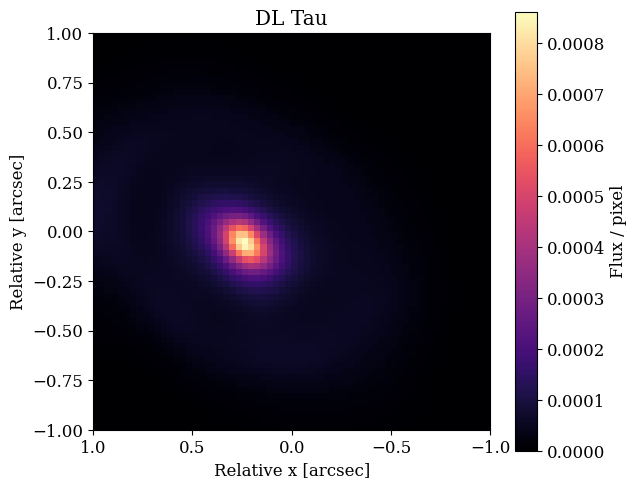

In [28]:
image = np.asarray(output[:, 0]).reshape(npix, npix)
fig, ax = plt.subplots(figsize=(6.4, 5.7))

plot = ax.imshow(
    image,
    origin='upper',
    extent=(fov_arcsec / 2, -fov_arcsec / 2, -fov_arcsec / 2, fov_arcsec / 2),
    cmap='magma', 
    interpolation='nearest', 
    vmin=0,
)

ax.set(
    xlabel='Relative x [arcsec]', 
    ylabel='Relative y [arcsec]', 
    title='DL Tau'
)

fig.colorbar(plot, ax=ax, label='Flux / pixel')
plt.show()

Example reference image:

![DL Tau disk image](https://www.circumstellardisks.org/imgs/DLTau_Long2018.jpg)